# Book-Crossing Recommender System with a Medallion Data Lake

**Objective:** Take the raw, messy Book-Crossing dataset (`Users`, `Books`, `Book-Ratings`) through a **Bronze → Silver → Gold** Medallion Data Lake pipeline and build an **Item-Based Collaborative Filtering** recommender system using the Gold layer.

## Step 1: Set Up the Data Lake and Build the Bronze Layer

- Create `bronze/`, `silver/`, and `gold/` directories.
- Download `book-crossings.zip` and load the three CSVs **as-is** using `;` separators and `latin-1` encoding (plus `escapechar='\\'` for escaped quotes in `BX-Books.csv`).
- Add an `ingestion_timestamp` column to each table and save to `bronze/` as Parquet without any cleaning.

In [1]:
import os
import zipfile
import urllib.request
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")

# Create Medallion Data Lake directories
for folder in ["raw_data", "bronze", "silver", "gold"]:
    os.makedirs(folder, exist_ok=True)

# Download Book-Crossing dataset if not already present
zip_path = "book-crossings.zip"
url = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
if not os.path.exists(zip_path):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as resp, open(zip_path, "wb") as out:
        out.write(resp.read())

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("raw_data")

print("Extracted files:", os.listdir("raw_data"))

Extracted files: ['BX-Book-Ratings.csv', 'BX-Books.csv', 'BX-Users.csv']


In [2]:
# Load raw CSV files exactly as they are (semicolon-separated, latin-1 encoding)
ingestion_ts = datetime.now(timezone.utc).isoformat()

users_raw = pd.read_csv(
    "raw_data/BX-Users.csv", sep=";", encoding="latin-1", low_memory=False
)
books_raw = pd.read_csv(
    "raw_data/BX-Books.csv", sep=";", encoding="latin-1", escapechar="\\", low_memory=False
)
ratings_raw = pd.read_csv(
    "raw_data/BX-Book-Ratings.csv", sep=";", encoding="latin-1", low_memory=False
)

# Add ingestion_timestamp without modifying or cleaning any source values
for df in (users_raw, books_raw, ratings_raw):
    df["ingestion_timestamp"] = ingestion_ts

# Save untouched Bronze tables as Parquet
users_raw.to_parquet("bronze/users.parquet", index=False)
books_raw.to_parquet("bronze/books.parquet", index=False)
ratings_raw.to_parquet("bronze/ratings.parquet", index=False)

print("Bronze layer saved:")
for fname in ["users.parquet", "books.parquet", "ratings.parquet"]:
    size_mb = os.path.getsize(os.path.join("bronze", fname)) / (1024 * 1024)
    print(f"  bronze/{fname}: {size_mb:.2f} MB")

Bronze layer saved:
  bronze/users.parquet: 4.15 MB
  bronze/books.parquet: 20.67 MB
  bronze/ratings.parquet: 9.36 MB


## Step 2: Explore the Bronze Data (EDA)

Read the Bronze Parquet tables back and inspect shapes, data types, missing values, rating distribution, age/publication-year anomalies, user/book rating counts, and matrix sparsity.

In [3]:
# Read Bronze tables back
bronze_users = pd.read_parquet("bronze/users.parquet")
bronze_books = pd.read_parquet("bronze/books.parquet")
bronze_ratings = pd.read_parquet("bronze/ratings.parquet")

for name, df in [("Users", bronze_users), ("Books", bronze_books), ("Ratings", bronze_ratings)]:
    print(f"=== {name} ===")
    print("Shape:", df.shape)
    print("Dtypes:\n", df.dtypes)
    print("Missing values:\n", df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print()

=== Users ===
Shape: (278858, 4)
Dtypes:
 User-ID                  int64
Location                   str
Age                    float64
ingestion_timestamp        str
dtype: object
Missing values:
 User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64
Duplicate rows: 0

=== Books ===
Shape: (271379, 9)
Dtypes:
 ISBN                     str
Book-Title               str
Book-Author              str
Year-Of-Publication    int64
Publisher                str
Image-URL-S              str
Image-URL-M              str
Image-URL-L              str
ingestion_timestamp      str
dtype: object
Missing values:
 ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
ingestion_timestamp    0
dtype: int64


Duplicate rows: 0

=== Ratings ===
Shape: (1149780, 4)
Dtypes:
 User-ID                int64
ISBN                     str
Book-Rating            int64
ingestion_timestamp      str
dtype: object
Missing values:
 User-ID                0
ISBN                   0
Book-Rating            0
ingestion_timestamp    0
dtype: int64


Duplicate rows: 0



In [4]:
# Distribution of ratings
rating_counts = bronze_ratings["Book-Rating"].value_counts().sort_index()
zero_count = (bronze_ratings["Book-Rating"] == 0).sum()
zero_pct = zero_count / len(bronze_ratings) * 100
print(f"Rating == 0 count: {zero_count:,} ({zero_pct:.2f}% of all ratings)")
print(f"Explicit ratings (1-10) count: {(bronze_ratings['Book-Rating'] > 0).sum():,}")
print("\nRating value counts:\n", rating_counts)

# User Ages & Publication Years
print("\nUser Age summary:")
print(bronze_users["Age"].describe())
print(f"Ages < 5: {(bronze_users['Age'] < 5).sum():,}, Ages > 100: {(bronze_users['Age'] > 100).sum():,}")

pub_years = pd.to_numeric(bronze_books["Year-Of-Publication"], errors="coerce")
print("\nPublication Year summary:")
print(pub_years.describe())
print(f"Year == 0: {(pub_years == 0).sum():,}, Year > 2026: {(pub_years > 2026).sum():,}")

# Ratings per user and per book
user_rating_cnt = bronze_ratings.groupby("User-ID").size()
book_rating_cnt = bronze_ratings.groupby("ISBN").size()
print("\nRatings per user quantiles:\n", user_rating_cnt.quantile([0.5, 0.75, 0.9, 0.95, 0.99]))
print("\nRatings per book quantiles:\n", book_rating_cnt.quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

# Matrix Sparsity
n_users = bronze_ratings["User-ID"].nunique()
n_books = bronze_ratings["ISBN"].nunique()
density_pct = len(bronze_ratings) / (n_users * n_books) * 100
sparsity_pct = 100.0 - density_pct
print(f"\nUnique users in ratings: {n_users:,}, Unique books in ratings: {n_books:,}")
print(f"Matrix density: {density_pct:.6f}% | Matrix sparsity: {sparsity_pct:.6f}%")

Rating == 0 count: 716,109 (62.28% of all ratings)
Explicit ratings (1-10) count: 433,671

Rating value counts:
 Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

User Age summary:
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64
Ages < 5: 882, Ages > 100: 366

Publication Year summary:
count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
Year == 0: 4,619, Year > 2026: 11



Ratings per user quantiles:
 0.50      1.0
0.75      4.0
0.90     12.0
0.95     29.0
0.99    174.0
dtype: float64

Ratings per book quantiles:
 0.50     1.0
0.75     2.0
0.90     6.0
0.95    10.0
0.99    36.0
dtype: float64

Unique users in ratings: 105,283, Unique books in ratings: 340,556
Matrix density: 0.003207% | Matrix sparsity: 99.996793%


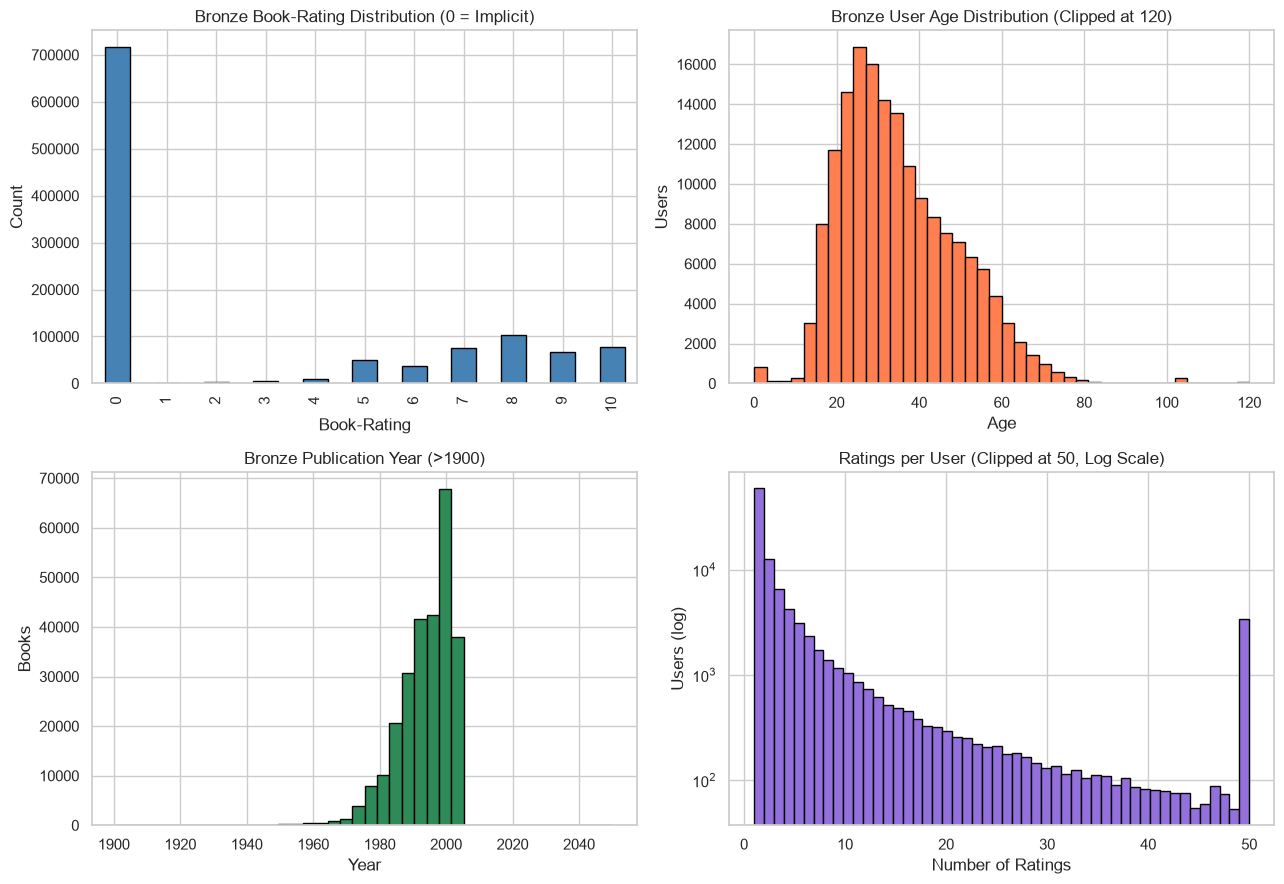

In [5]:
# Visualize key Bronze EDA distributions
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Rating distribution
rating_counts.plot(kind="bar", ax=axes[0, 0], color="steelblue", edgecolor="black")
axes[0, 0].set_title("Bronze Book-Rating Distribution (0 = Implicit)")
axes[0, 0].set_xlabel("Book-Rating")
axes[0, 0].set_ylabel("Count")

# 2. User Age distribution (clipped for readability)
bronze_users["Age"].dropna().clip(0, 120).hist(bins=40, ax=axes[0, 1], color="coral", edgecolor="black")
axes[0, 1].set_title("Bronze User Age Distribution (Clipped at 120)")
axes[0, 1].set_xlabel("Age")
axes[0, 1].set_ylabel("Users")

# 3. Publication Year distribution (excluding 0 for zoom)
pub_years[pub_years > 1900].clip(1900, 2050).hist(bins=40, ax=axes[1, 0], color="seagreen", edgecolor="black")
axes[1, 0].set_title("Bronze Publication Year (>1900)")
axes[1, 0].set_xlabel("Year")
axes[1, 0].set_ylabel("Books")

# 4. Ratings per user (log-scale y)
user_rating_cnt.clip(upper=50).hist(bins=50, ax=axes[1, 1], color="mediumpurple", edgecolor="black")
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Ratings per User (Clipped at 50, Log Scale)")
axes[1, 1].set_xlabel("Number of Ratings")
axes[1, 1].set_ylabel("Users (log)")

plt.tight_layout()
plt.show()

### Bronze EDA Findings & Silver Cleaning Plan

- **Shape, data types, and missing values:** `Users` has 278,858 rows (110,762 missing `Age`), `Books` has 271,379 rows (small nulls in `Book-Author`, `Publisher`, `Image-URL-L`), and `Ratings` has 1,149,780 rows with no nulls; in Silver, we will deduplicate all three tables, impute `Age`, drop unused image-URL columns, and standardize text columns.
- **Distribution of ratings:** 716,109 ratings (62.28%) are `0` (implicit/no explicit rating), leaving 433,671 explicit ratings (1–10); in Silver, we will remove all `0` ratings and keep only explicit ratings from `1` to `10`.
- **Distribution of user ages and publication years:** `Age` ranges from `0` to `244` (882 below 5, 366 above 100) and `Year-Of-Publication` has 4,619 zeros and 11 future years (> 2026, up to 2050); in Silver, we will set ages `< 5` or `> 100` to null and fill with the median age (`32.0`), and set publication years `0` or `> 2026` to null.
- **Number of ratings per user and per book:** 50% of users and 50% of books have only 1 rating (90th percentile is 12 for users and 6 for books); in Silver, we will filter to users and books with at least `10` explicit ratings so similarity estimates are reliable.
- **Matrix sparsity:** Only `0.003207%` of all possible user-book pairs in Bronze ratings are populated (`99.996793%` sparse); in Silver/Gold, we will store the filtered rating matrix as a `scipy.sparse` CSR matrix.

## Step 3: Clean the Data and Build the Silver Layer

Apply all cleaning rules, enforce referential integrity between `ratings`, `users`, and `books`, and filter to active users and books with at least `MIN_RATINGS = 10` explicit ratings.

**Threshold Choice & Justification:** Based on our Bronze EDA, 75% of users have ≤ 4 ratings and 90% of books have ≤ 6 ratings, while 62.28% of raw ratings are implicit zeros. Using `MIN_RATINGS = 10` (applied iteratively so every remaining user and book has ≥ 10 explicit ratings) removes cold-start noise and ensures each item vector has enough overlapping explicit ratings for meaningful cosine similarity.

In [6]:
# 1. Start from Bronze copies and drop ingestion_timestamp for clean domain tables (or keep metadata if desired)
silver_users = bronze_users.drop(columns=["ingestion_timestamp"]).drop_duplicates().copy()
silver_books = bronze_books.drop(columns=["ingestion_timestamp"]).drop_duplicates().copy()
silver_ratings = bronze_ratings.drop(columns=["ingestion_timestamp"]).drop_duplicates().copy()

# 2. Remove ratings of 0 and keep explicit ratings 1..10
silver_ratings = silver_ratings[silver_ratings["Book-Rating"].between(1, 10)].copy()

# 3. Fix user ages: < 5 or > 100 -> null, then fill nulls with median age
silver_users.loc[(silver_users["Age"] < 5) | (silver_users["Age"] > 100), "Age"] = np.nan
median_age = silver_users["Age"].median()
silver_users["Age"] = silver_users["Age"].fillna(median_age)

# 4. Split Location into city, state, country
loc_parts = silver_users["Location"].fillna("").astype(str).str.split(",", n=2, expand=True)
silver_users["city"] = loc_parts[0].str.strip().str.lower().replace("", np.nan)
silver_users["state"] = loc_parts[1].fillna("").str.strip().str.lower().replace("", np.nan)
silver_users["country"] = loc_parts[2].fillna("").str.strip().str.lower().replace("", np.nan)
silver_users = silver_users.drop(columns=["Location"])

# 5. Fix publication years: 0 or future years (> 2026) -> null
silver_books["Year-Of-Publication"] = pd.to_numeric(
    silver_books["Year-Of-Publication"], errors="coerce"
)
silver_books.loc[
    (silver_books["Year-Of-Publication"] <= 0) | (silver_books["Year-Of-Publication"] > 2026),
    "Year-Of-Publication",
] = np.nan

# 6. Clean text columns (strip extra spaces, standardise case) and drop Image-URL columns
silver_books = silver_books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])
for col in ["ISBN", "Book-Title", "Book-Author", "Publisher"]:
    silver_books[col] = (
        silver_books[col].fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
    )
    if col in ["Book-Title", "Book-Author", "Publisher"]:
        silver_books[col] = silver_books[col].str.title()

silver_ratings["ISBN"] = silver_ratings["ISBN"].astype(str).str.strip()
silver_users = silver_users.drop_duplicates(subset=["User-ID"])
silver_books = silver_books.drop_duplicates(subset=["ISBN"])
silver_ratings = silver_ratings.drop_duplicates(subset=["User-ID", "ISBN"])

# 7. Keep only ratings whose book and user exist in books and users tables
silver_ratings = silver_ratings[
    silver_ratings["User-ID"].isin(silver_users["User-ID"])
    & silver_ratings["ISBN"].isin(silver_books["ISBN"])
].copy()

# 8. Keep only users and books with at least MIN_RATINGS = 10 explicit ratings (iterative k-core)
MIN_RATINGS = 10
while True:
    u_counts = silver_ratings["User-ID"].value_counts()
    b_counts = silver_ratings["ISBN"].value_counts()
    filtered = silver_ratings[
        silver_ratings["User-ID"].isin(u_counts[u_counts >= MIN_RATINGS].index)
        & silver_ratings["ISBN"].isin(b_counts[b_counts >= MIN_RATINGS].index)
    ]
    if len(filtered) == len(silver_ratings):
        break
    silver_ratings = filtered.copy()

# Filter users and books tables to match active Silver ratings
silver_users = silver_users[silver_users["User-ID"].isin(silver_ratings["User-ID"])].copy()
silver_books = silver_books[silver_books["ISBN"].isin(silver_ratings["ISBN"])].copy()

# Save Silver tables to silver/
silver_users.to_parquet("silver/users.parquet", index=False)
silver_books.to_parquet("silver/books.parquet", index=False)
silver_ratings.to_parquet("silver/ratings.parquet", index=False)

print(f"Silver Users:   {silver_users.shape}")
print(f"Silver Books:   {silver_books.shape}")
print(f"Silver Ratings: {silver_ratings.shape}")
print(f"Silver Matrix Density: {len(silver_ratings) / (len(silver_users) * len(silver_books)) * 100:.2f}%")

Silver Users:   (1820, 5)
Silver Books:   (2030, 5)
Silver Ratings: (41456, 3)
Silver Matrix Density: 1.12%


## Step 4: Build the Gold Layer

From the Silver tables, create model-ready Gold artifacts and save them to `gold/`:
1. Sparse user-book rating matrix (`gold/user_book_matrix.npz`) with row/column ID mappings (`gold/user_index.parquet`, `gold/book_index.parquet`).
2. Book lookup table (`gold/book_lookup.parquet`) mapping `ISBN` (`book_id`), `title`, and `author`.
3. User-level and book-level aggregates (`gold/user_aggregates.parquet`, `gold/book_aggregates.parquet`) with average rating and rating count.

In [7]:
s_users = pd.read_parquet("silver/users.parquet")
s_books = pd.read_parquet("silver/books.parquet")
s_ratings = pd.read_parquet("silver/ratings.parquet")

# 1. Sparse User-Book Rating Matrix
user_ids = np.sort(s_ratings["User-ID"].unique())
book_isbns = np.sort(s_ratings["ISBN"].unique())

user_to_idx = {uid: i for i, uid in enumerate(user_ids)}
book_to_idx = {isbn: i for i, isbn in enumerate(book_isbns)}

row_idx = s_ratings["User-ID"].map(user_to_idx).to_numpy()
col_idx = s_ratings["ISBN"].map(book_to_idx).to_numpy()
vals = s_ratings["Book-Rating"].to_numpy(dtype=np.float32)

user_book_matrix = sparse.csr_matrix(
    (vals, (row_idx, col_idx)), shape=(len(user_ids), len(book_isbns))
)
sparse.save_npz("gold/user_book_matrix.npz", user_book_matrix)

pd.DataFrame({"user_idx": np.arange(len(user_ids)), "User-ID": user_ids}).to_parquet(
    "gold/user_index.parquet", index=False
)
pd.DataFrame({"book_idx": np.arange(len(book_isbns)), "ISBN": book_isbns}).to_parquet(
    "gold/book_index.parquet", index=False
)

# 2. Book Lookup Table
book_lookup = s_books[["ISBN", "Book-Title", "Book-Author"]].rename(
    columns={"ISBN": "book_id", "Book-Title": "title", "Book-Author": "author"}
)
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

# 3. User-level and Book-level Aggregates
user_agg = (
    s_ratings.groupby("User-ID")["Book-Rating"]
    .agg(avg_rating="mean", rating_count="count")
    .reset_index()
)
book_agg = (
    s_ratings.groupby("ISBN")["Book-Rating"]
    .agg(avg_rating="mean", rating_count="count")
    .reset_index()
    .merge(book_lookup, left_on="ISBN", right_on="book_id", how="left")
)

user_agg.to_parquet("gold/user_aggregates.parquet", index=False)
book_agg.to_parquet("gold/book_aggregates.parquet", index=False)

print("Gold layer saved:")
print("  User-Book sparse matrix shape:", user_book_matrix.shape, "nnz:", user_book_matrix.nnz)
print("  Book lookup shape:", book_lookup.shape)
print("  User aggregates shape:", user_agg.shape)
print("  Book aggregates shape:", book_agg.shape)

Gold layer saved:
  User-Book sparse matrix shape: (1820, 2030) nnz: 41456
  Book lookup shape: (2030, 3)
  User aggregates shape: (1820, 3)
  Book aggregates shape: (2030, 6)


## Step 5: Build the Recommender (Item-Based Collaborative Filtering)

1. Load the sparse rating matrix from `gold/` and transpose it so each row is a book and each column is a user.
2. Fit `NearestNeighbors(metric='cosine', algorithm='brute')` on the sparse book-user matrix.
3. Implement `similar_books(book_title, n=10)` to return the 10 most similar books.
4. Implement `recommend(user_id, n=10)` which finds books the user rated highly, gathers similar books, scores them by similarity weighted by the user's rating, excludes books already read by the user, and returns the top `n` titles.

In [8]:
# Load Gold layer artifacts
gold_matrix = sparse.load_npz("gold/user_book_matrix.npz")
user_index_df = pd.read_parquet("gold/user_index.parquet")
book_index_df = pd.read_parquet("gold/book_index.parquet")
book_lookup_df = pd.read_parquet("gold/book_lookup.parquet")

# Arrange matrix so rows = books, columns = users
book_user_matrix = gold_matrix.T.tocsr()

# Build fast lookup dicts
idx_to_isbn = dict(zip(book_index_df["book_idx"], book_index_df["ISBN"]))
isbn_to_idx = dict(zip(book_index_df["ISBN"], book_index_df["book_idx"]))
user_to_row = dict(zip(user_index_df["User-ID"], user_index_df["user_idx"]))
isbn_to_meta = book_lookup_df.set_index("book_id")[["title", "author"]].to_dict("index")

# Fit Item-Based Cosine NearestNeighbors
nn_model = NearestNeighbors(metric="cosine", algorithm="brute")
nn_model.fit(book_user_matrix)


def similar_books(book_title, n=10):
    """Return the top n most similar books for a given book title (case-insensitive substring/exact match)."""
    matches = book_lookup_df[
        book_lookup_df["title"].str.lower() == book_title.strip().lower()
    ]
    if matches.empty:
        matches = book_lookup_df[
            book_lookup_df["title"].str.lower().str.contains(book_title.strip().lower(), regex=False)
        ]
    if matches.empty:
        raise ValueError(f"Book title '{book_title}' not found in Gold catalog.")

    # Pick the matching edition with the most ratings if multiple ISBNs share a title
    target_isbn = matches.iloc[0]["book_id"]
    if target_isbn not in isbn_to_idx:
        raise ValueError(f"ISBN {target_isbn} not in rating matrix.")

    b_idx = isbn_to_idx[target_isbn]
    distances, indices = nn_model.kneighbors(book_user_matrix[b_idx], n_neighbors=n + 1)

    results = []
    for dist, idx in zip(distances.flatten()[1:], indices.flatten()[1:]):
        isbn = idx_to_isbn[int(idx)]
        meta = isbn_to_meta.get(isbn, {"title": "Unknown", "author": "Unknown"})
        results.append({
            "ISBN": isbn,
            "title": meta["title"],
            "author": meta["author"],
            "similarity": round(float(1.0 - dist), 4),
        })
    return pd.DataFrame(results)


def recommend(user_id, n=10, min_high_rating=7, k_neighbors=15):
    """Recommend top n unread books for user_id using rating-weighted item similarity."""
    if user_id not in user_to_row:
        raise ValueError(f"User-ID {user_id} not found in Gold matrix.")

    u_row = user_to_row[user_id]
    user_vec = gold_matrix[u_row]
    read_indices = set(user_vec.indices.tolist())

    # Identify books the user rated highly (fall back to top-rated if none >= min_high_rating)
    liked_pairs = [
        (int(idx), float(val))
        for idx, val in zip(user_vec.indices, user_vec.data)
        if val >= min_high_rating
    ]
    if not liked_pairs:
        liked_pairs = sorted(
            [(int(idx), float(val)) for idx, val in zip(user_vec.indices, user_vec.data)],
            key=lambda x: x[1],
            reverse=True,
        )[:5]

    scores = {}
    for b_idx, user_rating in liked_pairs:
        distances, indices = nn_model.kneighbors(
            book_user_matrix[b_idx], n_neighbors=k_neighbors + 1
        )
        for dist, nbr_idx in zip(distances.flatten()[1:], indices.flatten()[1:]):
            nbr_idx = int(nbr_idx)
            if nbr_idx in read_indices:
                continue
            sim = max(0.0, float(1.0 - dist))
            scores[nbr_idx] = scores.get(nbr_idx, 0.0) + sim * user_rating

    # Rank candidate books by weighted similarity score (deduplicating by title)
    ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    recs = []
    seen_titles = set()
    for b_idx, score in ranked:
        isbn = idx_to_isbn[b_idx]
        meta = isbn_to_meta.get(isbn, {"title": "Unknown", "author": "Unknown"})
        title_key = meta["title"].lower()
        if title_key in seen_titles:
            continue
        seen_titles.add(title_key)
        recs.append({
            "ISBN": isbn,
            "title": meta["title"],
            "author": meta["author"],
            "score": round(score, 4),
        })
        if len(recs) >= n:
            break

    return pd.DataFrame(recs)

## Step 6: Demo and Sanity Check

1. Test `similar_books()` on a popular title.
2. Run `recommend()` for three different users and display their highly rated books alongside the recommended titles.

In [9]:
# Sanity check: 10 most similar books to a popular title
print("Top 10 books similar to 'The Da Vinci Code':")
display(similar_books("The Da Vinci Code", n=10))

Top 10 books similar to 'The Da Vinci Code':


,ISBN,title,author,similarity
0,0671027360,Angels &Amp; Demons,Dan Brown,0.2398
1,0316666343,The Lovely Bones: A Novel,Alice Sebold,0.1783
2,0316155306,The Narrows: A Novel,Michael Connelly,0.1763
3,0374199698,Middlesex: A Novel,Jeffrey Eugenides,0.1749
4,0316780812,Sea Glass: A Novel,Anita Shreve,0.1616
5,0525947299,No Second Chance,Harlan Coben,0.1599
6,0553802488,The Face,Dean Koontz,0.1575
7,0446531332,Nights In Rodanthe,Nicholas Sparks,0.1560
8,0142001740,The Secret Life Of Bees,Sue Monk Kidd,0.1556
9,0345452577,The Conspiracy Club,Jonathan Kellerman,0.1506


In [10]:
# Select 3 diverse active users from Gold aggregates
user_agg_df = pd.read_parquet("gold/user_aggregates.parquet")
sample_users = (
    user_agg_df[user_agg_df["rating_count"].between(15, 60) & (user_agg_df["avg_rating"] >= 7.0)]
    .sort_values("rating_count", ascending=False)
    .head(3)["User-ID"]
    .tolist()
)

for uid in sample_users:
    u_row = user_to_row[uid]
    user_vec = gold_matrix[u_row]
    liked = sorted(
        [(int(idx), float(val)) for idx, val in zip(user_vec.indices, user_vec.data)],
        key=lambda x: x[1],
        reverse=True,
    )
    liked_df = pd.DataFrame([
        {
            "title": isbn_to_meta[idx_to_isbn[idx]]["title"],
            "author": isbn_to_meta[idx_to_isbn[idx]]["author"],
            "user_rating": rating,
        }
        for idx, rating in liked[:8]
    ])

    recs_df = recommend(uid, n=10)

    print("=" * 80)
    print(f"USER {uid} | Total Rated Books: {len(liked)}")
    print("-" * 80)
    print("Top Books Rated Highly by User:")
    display(liked_df)
    print("Top 10 Recommended Books:")
    display(recs_df)

USER 236340 | Total Rated Books: 60
--------------------------------------------------------------------------------
Top Books Rated Highly by User:


,title,author,user_rating
0,A Time To Kill,John Grisham,10.0
1,Hot Six : A Stephanie Plum Novel (A Stephanie ...,Janet Evanovich,9.0
2,Dr. Death (Alex Delaware Novels (Paperback)),Jonathan Kellerman,9.0
3,Cruel &Amp; Unusual (Kay Scarpetta Mysteries (...,Patricia D. Cornwell,9.0
4,Sanctuary (Peter Decker &Amp; Rina Lazarus Nov...,Faye Kellerman,9.0
5,Serpent'S Tooth : A Peter Decker/Rina Lazarus ...,Faye Kellerman,9.0
6,The Forgotten (Peter Decker &Amp; Rina Lazarus...,Faye Kellerman,9.0
7,The Body Farm,Patricia Daniels Cornwell,9.0


Top 10 Recommended Books:


,ISBN,title,author,score
0,0553284789,F Is For Fugitive (Kinsey Millhone Mysteries (...,Sue Grafton,22.5625
1,0553280368,C Is For Corpse (Kinsey Millhone Mysteries (Pa...,Sue Grafton,20.8657
2,0449221504,K Is For Killer (Kinsey Millhone Mysteries (Pa...,Sue Grafton,19.4380
3,0449221482,J Is For Judgment,Sue Grafton,18.5468
4,0425154092,From Potter'S Field,Patricia Daniels Cornwell,18.1079
5,0449221490,L Is For Lawless,Sue Grafton,16.3514
6,0380718332,All That Remains (Kay Scarpetta Mysteries (Pap...,Patricia D. Cornwell,16.2659
7,0425137562,Silent Prey,John Sandford,14.3539
8,0449003787,"""O"" Is For Outlaw",Sue Grafton,14.1746
9,0425180638,The Last Precinct,Patricia Cornwell,11.4021



USER 164323 | Total Rated Books: 59
--------------------------------------------------------------------------------
Top Books Rated Highly by User:


,title,author,user_rating
0,84 Charing Cross Road,Helene Hanff,10.0
1,The Lovely Bones: A Novel,Alice Sebold,9.0
2,Shoeless Joe,W. P. Kinsella,9.0
3,The Firm,John Grisham,9.0
4,A Time To Kill,John Grisham,9.0
5,The Martian Chronicles,Ray Bradbury,9.0
6,Anne Frank: The Diary Of A Young Girl,Anne Frank,9.0
7,Angels &Amp; Demons,Dan Brown,9.0


... (2 outputs left out)

USER 235282 | Total Rated Books: 58
--------------------------------------------------------------------------------
Top Books Rated Highly by User:


,title,author,user_rating
0,I Know This Much Is True (Oprah'S Book Club),Wally Lamb,10.0
1,I Know This Much Is True,Wally Lamb,10.0
2,The Vagina Monologues: The V-Day Edition,Eve Ensler,10.0
3,Gerald'S Game,Stephen King,10.0
4,Siddhartha,Hermann Hesse,10.0
5,The Bell Jar,Sylvia Plath,10.0
6,Naked,David Sedaris,9.0
7,The Probable Future,Alice Hoffman,9.0


Top 10 Recommended Books:


,ISBN,title,author,score
0,0671004549,You Belong To Me,Mary Higgins Clark,9.0815
1,0671014919,My Gal Sunday,Mary Higgins Clark,8.3355
2,0671004573,Before I Say Good-Bye,Mary Higgins Clark,7.8989
3,0385337639,Crow Lake (Today Show Book Club #7),Mary Lawson,7.8963
4,0743454529,"My Sister'S Keeper : A Novel (Picoult, Jodi)",Jodi Picoult,7.6261
5,042511984X,The Face Of Fear,Dean R. Koontz,7.4283
6,0425162443,The Rapture Of Canaan,Sheri Reynolds,7.2169
7,0671867113,Moonlight Becomes You,Mary Higgins Clark,7.1914
8,0671568175,Let Me Call You Sweetheart,Mary Higgins Clark,7.0044
9,055329170X,Time Bomb (Alex Delaware Novels (Paperback)),Jonathan Kellerman,6.3775
